In [143]:
import pandas as pd
import numpy as np
import glob
import matplotlib.pyplot as plt
import seaborn as sns

In [85]:
csv_list = glob.glob("brasil-real-estate-*.csv")
print(csv_list)


['brasil-real-estate-1.csv', 'brasil-real-estate-2.csv']


In [10]:
import os

print(os.getcwd())

C:\Users\DELL-USER\Documents\July_cohort_data_science VS


In [7]:
import os
os.chdir(r"C:\Users\DELL-USER\Documents\July_cohort_data_science VS")

In [86]:
dataframe = [pd.read_csv(file) for file in csv_list]

In [ ]:
dataframe.head()

In [87]:
df1 = dataframe[0]
df2 = dataframe [1]

In [ ]:
df1.head()


,property_type,place_with_parent_names,region,lat-lon,area_m2,price_usd
0,apartment,|Brasil|Alagoas|Maceió|,Northeast,"-9.6443051,-35.7088142",110.0,"$187,230.85"
1,apartment,|Brasil|Alagoas|Maceió|,Northeast,"-9.6430934,-35.70484",65.0,"$81,133.37"
2,house,|Brasil|Alagoas|Maceió|,Northeast,"-9.6227033,-35.7297953",211.0,"$154,465.45"
3,apartment,|Brasil|Alagoas|Maceió|,Northeast,"-9.622837,-35.719556",99.0,"$146,013.20"
4,apartment,|Brasil|Alagoas|Maceió|,Northeast,"-9.654955,-35.700227",55.0,"$101,416.71"


In [22]:
df1.shape

(12834, 6)

In [23]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12834 entries, 0 to 12833
Data columns (total 6 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   property_type            12834 non-null  object 
 1   place_with_parent_names  12834 non-null  object 
 2   region                   12834 non-null  object 
 3   lat-lon                  11551 non-null  object 
 4   area_m2                  12834 non-null  float64
 5   price_usd                12834 non-null  object 
dtypes: float64(1), object(5)
memory usage: 601.7+ KB


In [24]:
df1.duplicated()

0        False
1        False
2        False
3        False
4        False
         ...  
12829    False
12830    False
12831    False
12832    False
12833    False
Length: 12834, dtype: bool

In [25]:
df1.isna().sum()

property_type                 0
place_with_parent_names       0
region                        0
lat-lon                    1283
area_m2                       0
price_usd                     0
dtype: int64

In [26]:
df1.describe()

,area_m2
count,12834.000000
mean,116.687003
std,48.260754
min,53.000000
25%,78.000000
50%,105.000000
75%,145.000000
max,252.000000


In [105]:
from numpy import astype
from sympy import expand


clean_df1 = (
    df1
    .dropna()
    .reset_index(drop=True)
    .assign(price_usd = lambda x : x["price_usd"].str.replace("$", "").str.replace(",","").astype(float))
    .assign(state = lambda x:x["place_with_parent_names"].str.split("|",expand=True)[2])
    .assign(city = lambda x:x ["place_with_parent_names"].str.split("|", expand=True)[3])
    .assign(lat = lambda x:x ["lat-lon"].str.split(",", expand=True)[0].astype(float))
    .assign(lon = lambda x:x ["lat-lon"].str.split(",", expand=True)[1].astype(float))
    .assign(view_map=lambda x: '<a href="https://www.google.com/maps/search/?api=1&query=' + x["lat"].astype(str) + ',' + x["lon"].astype(str) + '" target="_blank">Open Map</a>')
    .drop(columns=["place_with_parent_names","lat-lon","city"])
    .reset_index(drop=True)
    
)

In [ ]:
from IPython.display import display, HTML

mapped_df1 = display(HTML(clean_df1.to_html(escape=False, index=False)))
mapped_df1 = clean_df1.copy()
mapped_df1.head()

In [68]:
display(HTML(mapped_df1.head(10).to_html(escape=False, index=False)))

property_type,region,area_m2,price_usd,state,lat,lon,view_map
apartment,Northeast,110.0,187230.85,Alagoas,-9.644305,-35.708814,Open Map
apartment,Northeast,65.0,81133.37,Alagoas,-9.643093,-35.704840,Open Map
house,Northeast,211.0,154465.45,Alagoas,-9.622703,-35.729795,Open Map
apartment,Northeast,99.0,146013.20,Alagoas,-9.622837,-35.719556,Open Map
apartment,Northeast,55.0,101416.71,Alagoas,-9.654955,-35.700227,Open Map
apartment,Northeast,56.0,75727.07,Alagoas,-9.614414,-35.735621,Open Map
apartment,Northeast,68.0,110916.18,Alagoas,-9.584755,-35.662909,Open Map
apartment,Northeast,187.0,249641.14,Alagoas,-9.658285,-35.703827,Open Map
apartment,Northeast,90.0,115459.02,Alagoas,-9.660820,-35.702976,Open Map
apartment,Northeast,137.0,361979.65,Alagoas,-9.663800,-35.711545,Open Map


In [90]:
clean_df1.head()

,property_type,region,area_m2,price_usd,state,lat,lon,view_map
0,apartment,Northeast,110.0,187230.85,Alagoas,-9.644305,-35.708814,"<a href=""https://www.google.com/maps/search/?a..."
1,apartment,Northeast,65.0,81133.37,Alagoas,-9.643093,-35.704840,"<a href=""https://www.google.com/maps/search/?a..."
2,house,Northeast,211.0,154465.45,Alagoas,-9.622703,-35.729795,"<a href=""https://www.google.com/maps/search/?a..."
3,apartment,Northeast,99.0,146013.20,Alagoas,-9.622837,-35.719556,"<a href=""https://www.google.com/maps/search/?a..."
4,apartment,Northeast,55.0,101416.71,Alagoas,-9.654955,-35.700227,"<a href=""https://www.google.com/maps/search/?a..."


In [91]:
df1.head()

,property_type,place_with_parent_names,region,lat-lon,area_m2,price_usd
0,apartment,|Brasil|Alagoas|Maceió|,Northeast,"-9.6443051,-35.7088142",110.0,"$187,230.85"
1,apartment,|Brasil|Alagoas|Maceió|,Northeast,"-9.6430934,-35.70484",65.0,"$81,133.37"
2,house,|Brasil|Alagoas|Maceió|,Northeast,"-9.6227033,-35.7297953",211.0,"$154,465.45"
3,apartment,|Brasil|Alagoas|Maceió|,Northeast,"-9.622837,-35.719556",99.0,"$146,013.20"
4,apartment,|Brasil|Alagoas|Maceió|,Northeast,"-9.654955,-35.700227",55.0,"$101,416.71"


In [ ]:
df2.head()

,property_type,state,region,lat,lon,area_m2,price_brl
0,apartment,Pernambuco,Northeast,-8.134204,-34.906326,72.0,414222.98
1,apartment,Pernambuco,Northeast,-8.126664,-34.903924,136.0,848408.53
2,apartment,Pernambuco,Northeast,-8.125550,-34.907601,75.0,299438.28
3,apartment,Pernambuco,Northeast,-8.120249,-34.895920,187.0,848408.53
4,apartment,Pernambuco,Northeast,-8.142666,-34.906906,80.0,464129.36


In [ ]:
df2 = df2.dropna()
df2.info()
df2 = df2.reset_index()


<class 'pandas.core.frame.DataFrame'>
Index: 11293 entries, 0 to 12832
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   property_type  11293 non-null  object 
 1   state          11293 non-null  object 
 2   region         11293 non-null  object 
 3   lat            11293 non-null  float64
 4   lon            11293 non-null  float64
 5   area_m2        11293 non-null  float64
 6   price_brl      11293 non-null  float64
dtypes: float64(4), object(3)
memory usage: 705.8+ KB


In [30]:
clean_df2 = (
    df2
    .dropna()
    .reset_index(drop=True)
    .assign(price_usd = lambda x:x["price_brl"] / 5.39)
    .drop(columns= ["price_brl"])
    .loc[:,["property_type", "region", "area_m2", "price_usd", "state","lat","lon"]]
    
    
)

In [31]:
clean_df2.head()

,property_type,region,area_m2,price_usd,state,lat,lon
0,apartment,Northeast,72.0,76850.274583,Pernambuco,-8.134204,-34.906326
1,apartment,Northeast,136.0,157404.179963,Pernambuco,-8.126664,-34.903924
2,apartment,Northeast,75.0,55554.411874,Pernambuco,-8.125550,-34.907601
3,apartment,Northeast,187.0,157404.179963,Pernambuco,-8.120249,-34.895920
4,apartment,Northeast,80.0,86109.343228,Pernambuco,-8.142666,-34.906906


In [ ]:
df2.head()

,index,property_type,state,region,lat,lon,area_m2,price_brl
0,0,apartment,Pernambuco,Northeast,-8.134204,-34.906326,72.0,414222.98
1,1,apartment,Pernambuco,Northeast,-8.126664,-34.903924,136.0,848408.53
2,2,apartment,Pernambuco,Northeast,-8.125550,-34.907601,75.0,299438.28
3,3,apartment,Pernambuco,Northeast,-8.120249,-34.895920,187.0,848408.53
4,4,apartment,Pernambuco,Northeast,-8.142666,-34.906906,80.0,464129.36


In [ ]:
clean_df1.head(10)

,property_type,region,area_m2,price_usd,state,lat,lon
0,apartment,Northeast,110.0,187230.85,Alagoas,-9.644305,-35.708814
1,apartment,Northeast,65.0,81133.37,Alagoas,-9.643093,-35.704840
2,house,Northeast,211.0,154465.45,Alagoas,-9.622703,-35.729795
3,apartment,Northeast,99.0,146013.20,Alagoas,-9.622837,-35.719556
4,apartment,Northeast,55.0,101416.71,Alagoas,-9.654955,-35.700227
5,apartment,Northeast,56.0,75727.07,Alagoas,-9.614414,-35.735621
6,apartment,Northeast,68.0,110916.18,Alagoas,-9.584755,-35.662909
7,apartment,Northeast,187.0,249641.14,Alagoas,-9.658285,-35.703827
8,apartment,Northeast,90.0,115459.02,Alagoas,-9.660820,-35.702976
9,apartment,Northeast,137.0,361979.65,Alagoas,-9.663800,-35.711545


In [ ]:
clean_df2.head()

,property_type,region,area_m2,price_usd,state,lat,lon
0,apartment,Northeast,72.0,76850.274583,Pernambuco,-8.134204,-34.906326
1,apartment,Northeast,136.0,157404.179963,Pernambuco,-8.126664,-34.903924
2,apartment,Northeast,75.0,55554.411874,Pernambuco,-8.125550,-34.907601
3,apartment,Northeast,187.0,157404.179963,Pernambuco,-8.120249,-34.895920
4,apartment,Northeast,80.0,86109.343228,Pernambuco,-8.142666,-34.906906


In [32]:
assert set(clean_df1.columns.tolist()) == set(clean_df2.columns.tolist()), "Both dataframe columns must be the same"

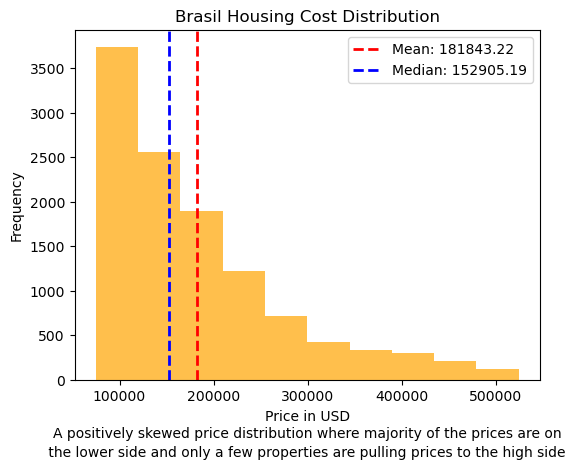

In [103]:
from matplotlib.lines import lineStyles


fig, ax = plt.subplots(figsize= (6, 4))
ax.hist(clean_df1["price_usd"], color= "orange", alpha= 0.7, bins=10)
ax.axvline(clean_df1["price_usd"].mean(), color="red", linestyle = "--", linewidth = 2, label = f"Mean: {clean_df1["price_usd"].mean():.2f}")
ax.axvline(np.median(clean_df1["price_usd"]), color="blue", linestyle = "--", linewidth = 2, label = f"Median: {np.median(clean_df1["price_usd"]):.2f}")
ax.set_xlabel("Price in USD")
ax.set_ylabel("Frequency")
ax.set_title("Brasil Housing Cost Distribution")
ax.text(0.5,-0.22, "A positively skewed price distribution where majority of the prices are on\n"\
" the lower side and only a few properties are pulling prices to the high side ", transform=ax.transAxes, ha="center", fontsize=10, linespacing=1.5)
ax.legend();

plt.subplots_adjust(bottom=0.005)


In [34]:
clean_df1.describe()

,area_m2,price_usd,lat,lon
count,11551.000000,11551.000000,11551.000000,11551.000000
mean,116.695264,181843.221930,-16.182759,-43.942239
std,48.186630,96603.990393,7.254958,5.001383
min,53.000000,74892.340000,-29.995461,-60.057747
25%,78.000000,109217.990000,-20.365431,-49.236000
50%,105.000000,152905.190000,-18.913077,-43.944378
75%,145.000000,224677.020000,-12.971690,-38.506627
max,252.000000,524246.390000,0.020423,-34.804455


In [35]:
clean_df1["property_type"].unique()

array(['apartment', 'house'], dtype=object)

In [36]:
categories = clean_df1["property_type"].value_counts().index.tolist()
values = clean_df1["property_type"].value_counts().values

In [37]:
categories[0]

'apartment'

In [38]:
values

array([9625, 1926])

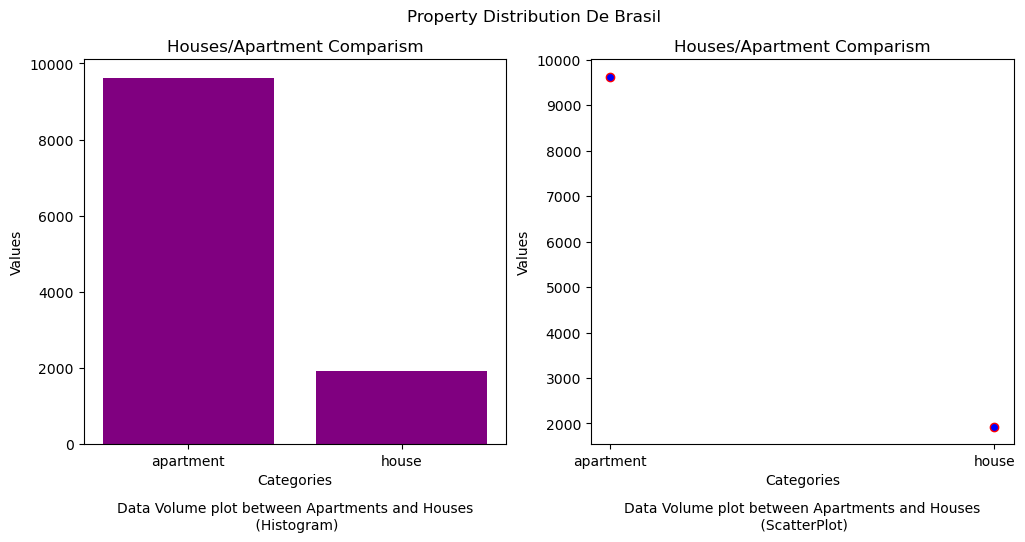

In [121]:
fig, ax = plt.subplots(1,2, figsize = (12,5))
ax[0].bar(categories, values, color="purple")
ax[0].set_xlabel("Categories")
ax[0].set_ylabel("Values")
ax[0].set_title("Houses/Apartment Comparism")
ax[0].text(0.5, -0.22, "Data Volume plot between Apartments and Houses\n (Histogram)", transform = ax[0].transAxes, ha="center", fontsize=10)

ax[1].scatter(categories, values, color="blue", edgecolor = "red")
ax[1].set_xlabel("Categories")
ax[1].set_ylabel("Values")
ax[1].set_title("Houses/Apartment Comparism")
ax[1].text(1.7, -0.22, "Data Volume plot between Apartments and Houses\n (ScatterPlot)", transform = ax[0].transAxes, ha="center", fontsize=10)


plt.suptitle("Property Distribution De Brasil");



In [ ]:
clean_df1.head()

,property_type,region,area_m2,price_usd,state,lat,lon
0,apartment,Northeast,110.0,187230.85,Alagoas,-9.644305,-35.708814
1,apartment,Northeast,65.0,81133.37,Alagoas,-9.643093,-35.704840
2,house,Northeast,211.0,154465.45,Alagoas,-9.622703,-35.729795
3,apartment,Northeast,99.0,146013.20,Alagoas,-9.622837,-35.719556
4,apartment,Northeast,55.0,101416.71,Alagoas,-9.654955,-35.700227


In [40]:
categories = clean_df1["property_type"].value_counts().index.tolist()

apartment = clean_df1[clean_df1["property_type"] == "apartment"]
house = clean_df1[clean_df1["property_type"]=="house"]

In [41]:
apartment.shape

(9625, 7)

In [42]:
house.shape

(1926, 7)

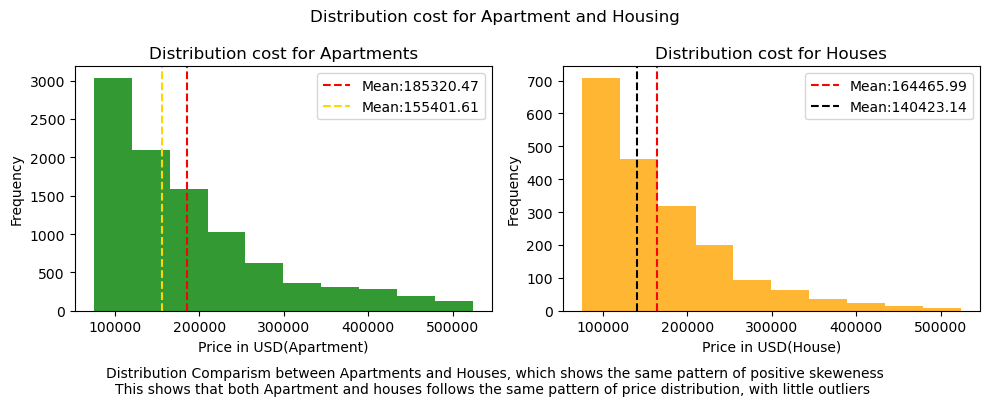

In [132]:
from turtle import color


fig, ax = plt.subplots(1, 2, figsize = (10,4))
ax[0].hist(apartment["price_usd"], color="green", alpha= 0.8)
ax[0].axvline(apartment["price_usd"].mean(), linestyle="--", color="red", label = f"Mean:{apartment["price_usd"].mean():.2f}")
ax[0].axvline(np.median(apartment["price_usd"]), linestyle="--", color="gold", label = f"Mean:{np.median(apartment["price_usd"]):.2f}")
ax[0].set_xlabel("Price in USD(Apartment)")
ax[0].set_ylabel("Frequency")
ax[0].set_title("Distribution cost for Apartments")
ax[0].legend()

ax[1].hist(house["price_usd"], color="orange", alpha= 0.8)
ax[1].axvline(house["price_usd"].mean(), linestyle="--", color="red", label = f"Mean:{house["price_usd"].mean():.2f}")
ax[1].axvline(np.median(house["price_usd"]), linestyle="--", color="black", label = f"Mean:{np.median(house["price_usd"]):.2f}")
ax[1].set_xlabel("Price in USD(House)")
ax[1].set_ylabel("Frequency")
ax[1].set_title("Distribution cost for Houses")
ax[1].legend()

fig.text(
    0.5, 0.02,
    "Distribution Comparism between Apartments and Houses, which shows the same pattern of positive skeweness\n" \
    "This shows that both Apartment and houses follows the same pattern of price distribution, with little outliers ",
    ha="center", fontsize=10)

plt.suptitle("Distribution cost for Apartment and Housing")
plt.tight_layout(rect=[0, 0.08, 1, 1])
plt.show()



In [ ]:
df2.head()

,index,property_type,state,region,lat,lon,area_m2,price_brl
0,0,apartment,Pernambuco,Northeast,-8.134204,-34.906326,72.0,414222.98
1,1,apartment,Pernambuco,Northeast,-8.126664,-34.903924,136.0,848408.53
2,2,apartment,Pernambuco,Northeast,-8.125550,-34.907601,75.0,299438.28
3,3,apartment,Pernambuco,Northeast,-8.120249,-34.895920,187.0,848408.53
4,4,apartment,Pernambuco,Northeast,-8.142666,-34.906906,80.0,464129.36


In [44]:
clean_df2["state"].unique

<bound method Series.unique of 0        Pernambuco
1        Pernambuco
2        Pernambuco
3        Pernambuco
4        Pernambuco
            ...    
11288     São Paulo
11289     São Paulo
11290     São Paulo
11291     São Paulo
11292     Tocantins
Name: state, Length: 11293, dtype: object>

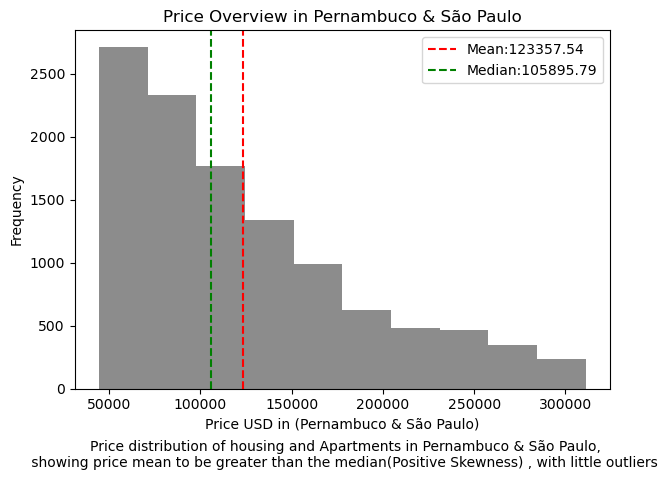

In [142]:
from matplotlib.pyplot import xlabel


fig, ax= plt.subplots(figsize = (7,4))
ax.hist(clean_df2["price_usd"], color= "grey", alpha= 0.9)
ax.axvline(clean_df2["price_usd"].mean(), linestyle= "--", color= "red", label= f"Mean:{clean_df2["price_usd"].mean():.2f}")
ax.axvline(np.median(clean_df2["price_usd"]), linestyle= "--", color= "green", label= f"Median:{np.median(clean_df2["price_usd"]):.2f}")
ax.set_xlabel("Price USD in (Pernambuco & São Paulo)")
ax.set_ylabel("Frequency")
ax.set_title("Price Overview in Pernambuco & São Paulo")
ax.legend()

fig.text(
    0.5, 0.02,
    "Price distribution of housing and Apartments in Pernambuco & São Paulo,\n" \
    " showing price mean to be greater than the median(Positive Skewness) , with little outliers ",
    ha="center", fontsize=10)

plt.tight_layout(rect=[0, 0.07, 0.9, 1.2])
plt.show()


In [ ]:
clean_df2.describe()

,area_m2,price_usd,lat,lon
count,11293.000000,11293.000000,11293.000000,11293.000000
mean,113.306916,123357.536222,-24.709566,-46.766914
std,47.225496,64334.739167,5.348853,4.205313
min,53.000000,44443.530612,-33.692432,-63.905184
25%,75.000000,72220.736549,-27.750971,-49.263866
50%,101.000000,105895.788497,-23.687193,-46.845531
75%,140.000000,157719.766234,-22.956369,-43.360840
max,252.000000,311104.730983,-5.044685,-34.841721


In [ ]:
!pip install Folium

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip
